# SynthFair on Adult, German Credit and COMPAS

This notebook tests whether the first SynthFair strategy narrows the absolute difference in positive prediction rates between two intersecting demographic groups. It compares two random forests fitted on the same real training split. One also receives synthetic training examples. Section 6 reproduces the counts and the figure in the report.

[Hattatoğlu et al., SynthFair](https://doi.org/10.1007/978-3-031-85856-7_26) · [Original implementation](https://github.com/bendiste/Algorithmic-Fairness/tree/e3d343f18ef98f67ad99e616ec389f215c41d12a/Implementation)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from prince import FAMD
from skfuzzy.cluster import cmeans
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

DATA = Path("data")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
SEEDS = (42, 43, 44)
CLUSTERS = {"Adult": 6, "German Credit": 3, "COMPAS": 5}
pd.options.display.float_format = "{:.4f}".format

## 1. Records, groups and outcomes

Two binary attributes define groups 0–3. Group 0 has neither reference value and group 3 has both. Group 1 has only the second value, and group 2 only the first. The outcome splits each group into two training cells. Group and outcome codes are kept outside the predictor matrix.

For Adult the reference values are male and White. For COMPAS they are female and Caucasian, using the dataset's labels. For German Credit I use age ≥40 from Table 3 of the paper and the public benchmark's personal-status code partition. The corrected UCI documentation says this field combines sex and marital status, so this comparison cannot identify a gender effect. I report the actual codes.

In [2]:
adult_cols = "age workclass fnlwgt education education_num marital_status occupation relationship race sex capital_gain capital_loss hours native_country income".split()
adult = pd.concat([
    pd.read_csv(DATA / "adult.data", names=adult_cols, skipinitialspace=True, na_values="?"),
    pd.read_csv(DATA / "adult.test", names=adult_cols, skipinitialspace=True, na_values="?", skiprows=1),
], ignore_index=True).dropna().reset_index(drop=True)
adult_income = adult.income.str.rstrip(".")
assert set(adult_income) == {"<=50K", ">50K"}

credit_cols = "checking months history purpose amount savings employment installment status_code debtors residence property age other_plans housing credits job dependents telephone foreign_worker credit".split()
credit = pd.read_csv(DATA / "german.data", sep=r"\s+", names=credit_cols)
status_ref = credit.status_code.isin(["A91", "A93", "A94"])
assert set(credit.status_code) <= {"A91", "A92", "A93", "A94", "A95"}
assert set(credit.credit) == {1, 2}

source = pd.read_csv(DATA / "compas-scores-two-years.csv", keep_default_na=False)
compas = source.loc[
    pd.to_numeric(source.days_b_screening_arrest, errors="coerce").between(-30, 30)
    & source.is_recid.ne(-1) & source.c_charge_degree.ne("O")
    & ~source.score_text.isin(["", "N/A"])
].reset_index(drop=True)
assert set(compas.two_year_recid) == {0, 1}

def group_id(first, second):
    return 2 * first.to_numpy(dtype=int) + second.to_numpy(dtype=int)

datasets = {
    "Adult": (
        adult.drop(columns=["sex", "race", "income", "fnlwgt", "education_num", "native_country"]),
        adult_income.eq(">50K").to_numpy(dtype=int),
        group_id(adult.sex.eq("Male"), adult.race.eq("White")),
    ),
    "German Credit": (
        credit.drop(columns=["age", "status_code", "credit"]),
        credit.credit.eq(1).to_numpy(dtype=int),
        group_id(credit.age.ge(40), status_ref),
    ),
    "COMPAS": (
        compas[["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count", "c_charge_degree"]],
        compas.two_year_recid.eq(0).to_numpy(dtype=int),
        group_id(compas.sex.eq("Female"), compas.race.eq("Caucasian")),
    ),
}
for name, (features, outcome, group) in datasets.items():
    assert features.notna().all().all() and set(2 * group + outcome) == set(range(8))
    print(name, len(outcome), "real records;", features.shape[1], "predictors")

Adult 45222 real records; 9 predictors
German Credit 1000 real records; 18 predictors
COMPAS 6172 real records; 6 predictors


## 2. Fairness before fitting a classifier

The positive-rate difference is group 0 minus group 3. The ratio divides those same rates. Equal rates give a difference of zero and a ratio of one. I also keep the rates of the two middle groups. Consistency measures agreement with the labels of five nearest neighbours across the dataset. Euclidean distances use standardized numbers and one-hot categories. As in AIF360, the query is eligible as a neighbour. The full-data calculation is descriptive. The model experiment fits a fresh encoder using only its training split.

In [3]:
def encoder(frame):
    numbers = list(frame.select_dtypes(include="number"))
    categories = [c for c in frame if c not in numbers]
    return ColumnTransformer([
        ("numeric", StandardScaler(), numbers),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories),
    ])

def closest_five(matrix):
    search = NearestNeighbors(n_neighbors=5, algorithm="ball_tree", n_jobs=1).fit(matrix)
    return search.kneighbors(matrix, return_distance=False)

def measure(name, seed, stage, values, groups, neighbours, truth=None):
    rates = [values[groups == g].mean() for g in range(4)]
    row = {"dataset": name, "seed": seed, "stage": stage, "n": len(values)}
    for g, rate in enumerate(rates):
        row[f"n{g}"] = int((groups == g).sum())
        row[f"rate{g}"] = rate
    row.update(dp_diff=rates[0] - rates[3], dir=rates[0] / rates[3] if rates[3] else np.nan,
               consistency=1 - np.abs(values - values[neighbours].mean(axis=1)).mean())
    if truth is not None:
        row.update(accuracy=accuracy_score(truth, values), balanced_accuracy=balanced_accuracy_score(truth, values))
    return row

original = []
for name, (frame, outcome, group) in datasets.items():
    matrix = encoder(frame).fit_transform(frame)
    original.append(measure(name, None, "Original labels (all)", outcome, group, closest_five(matrix)))
display(pd.DataFrame(original).set_index("dataset")[["n", "rate0", "rate1", "rate2", "rate3", "dp_diff", "dir", "consistency"]])

,n,rate0,rate1,rate2,rate3,dp_diff,dir,consistency
dataset,,,,,,,,
Adult,45222,0.0761,0.1224,0.2244,0.3239,-0.2478,0.2350,0.8367
German Credit,1000,0.6017,0.7261,0.8116,0.7174,-0.1157,0.8387,0.7396
COMPAS,6172,0.4834,0.5978,0.6494,0.6473,-0.1639,0.7468,0.6391


## 3. SynthFair training data

Following the authors’ public scripts, I project mixed training features onto two FAMD dimensions, fit fuzzy c-means and assign each row to the cluster with the highest membership. The authors use six clusters for Adult, three for German Credit and five for COMPAS. A cell with a single example cannot supply its own SMOTE neighbour. I move such examples to the nearest cluster with at least two examples from the same cell. If every occupied cluster has only one, I pool those examples in one of the occupied clusters. A cell absent from a cluster stays absent.

Inside each cluster, SMOTE interpolates between neighbours in the same demographic group **and** outcome, using one nearest neighbour as in the authors’ code. I balance the cells present there to the largest local count, keep the original labels, and pool the clusters to fit one model (Strategy 1). Interpolation in the encoded space can produce fractional category indicators. These are model inputs, not literal new people.

In [4]:
def fix_singletons(cluster, joint, projection, centers):
    cluster = cluster.copy()
    for cell in np.unique(joint):
        rows = np.flatnonzero(joint == cell)
        counts = np.bincount(cluster[rows], minlength=len(centers))
        destinations = np.flatnonzero(counts >= 2)
        if not len(destinations):
            if len(rows) < 2:
                raise ValueError(f"Training cell {cell} has fewer than two rows")
            cluster[rows] = cluster[rows[0]]
            continue
        for row in rows[counts[cluster[rows]] == 1]:
            distance = np.linalg.norm(centers[destinations] - projection[row], axis=1)
            cluster[row] = destinations[np.argmin(distance)]
    return cluster

def synthfair(frame, encoded, y, groups, k, seed):
    # Prince recognises numeric FAMD inputs by floating-point dtype.
    mixed = frame.astype({column: float for column in frame.select_dtypes(include="number")})
    projection = FAMD(n_components=2, random_state=seed).fit_transform(mixed).to_numpy()
    centers, membership, _, _, _, _, fpc = cmeans(
        projection.T, c=k, m=2, error=0.005, maxiter=5000, seed=seed
    )
    joint = 2 * groups + y
    first_cluster = membership.argmax(axis=0)
    cluster = fix_singletons(first_cluster, joint, projection, centers)
    matrices, outcomes, audit = [], [], []
    for cluster_id in np.unique(cluster):
        mask = cluster == cluster_id
        x_part, cell_part = encoded[mask], joint[mask]
        original_counts = np.bincount(cell_part, minlength=8)
        present = original_counts > 0
        assert original_counts[present].min() >= 2
        if original_counts[present].min() != original_counts.max():
            smote = SMOTE(k_neighbors=1, random_state=seed + int(cluster_id))
            x_aug, cell_aug = smote.fit_resample(x_part, cell_part)
        else:
            x_aug, cell_aug = x_part, cell_part
        np.testing.assert_array_equal(cell_aug[:len(cell_part)], cell_part)
        np.testing.assert_array_equal(x_aug[:len(x_part)], x_part)
        counts = np.bincount(cell_aug, minlength=8)
        np.testing.assert_array_equal(counts, present * original_counts.max())
        for cell in range(8):
            audit.append({"cluster": int(cluster_id), "group": cell // 2, "label": cell % 2,
                          "real_train": original_counts[cell], "after": counts[cell]})
        matrices.append(x_aug)
        outcomes.append(cell_aug % 2)
    return np.vstack(matrices), np.concatenate(outcomes), audit, fpc, int((cluster != first_cluster).sum())

## 4. Held-out comparison

For seeds 42, 43 and 44, I split the real records 70/30, stratifying on all eight group–label combinations. Each baseline and SynthFair pair receives the same predictors, training split and untouched test people. Both use a forest with 100 trees, a minimum of five observations per leaf and the same random seed. The test features are transformed with the training encoder. Test outcomes and demographic groups are used only to check the split and evaluate predictions. The first split is the main result. The other two show how sensitive it is to the split and random seed.

In [5]:
metrics = list(original)
cluster_rows, run_rows = [], []
main_split_rows = []
for name, (frame, outcome, groups) in datasets.items():
    for seed in SEEDS:
        train, test = train_test_split(np.arange(len(frame)), test_size=0.30, random_state=seed,
                                       stratify=2 * groups + outcome)
        assert not np.intersect1d(train, test).size and len(train) + len(test) == len(frame)
        train_frame = frame.iloc[train].reset_index(drop=True)
        transform = encoder(train_frame)
        x_train = transform.fit_transform(train_frame)
        x_test = transform.transform(frame.iloc[test])
        neighbours = closest_five(x_test)
        metrics.append(measure(name, seed, "Actual test labels", outcome[test], groups[test], neighbours))
        with threadpool_limits(limits=1):
            x_aug, y_aug, audit, fpc, moved = synthfair(
                train_frame, x_train, outcome[train], groups[train], CLUSTERS[name], seed
            )
        assert sum(r["real_train"] for r in audit) == len(train)
        assert sum(r["after"] for r in audit) == len(y_aug)
        cluster_rows.extend(dict(dataset=name, seed=seed, **row) for row in audit)
        run_rows.append(dict(dataset=name, seed=seed, real_train=len(train), real_test=len(test),
                             synthetic=len(y_aug)-len(train), fpc=fpc, moved=moved))
        paired_predictions = {}
        for stage, x_fit, y_fit in [("Baseline", x_train, outcome[train]), ("SynthFair", x_aug, y_aug)]:
            forest = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=seed, n_jobs=3)
            forest.fit(x_fit, y_fit)
            pred = forest.predict(x_test)
            metrics.append(measure(name, seed, stage, pred, groups[test], neighbours, outcome[test]))
            if seed == SEEDS[0]:
                paired_predictions[stage] = pred

        if seed == SEEDS[0]:
            main_split_rows.append(pd.DataFrame({
                "dataset": name, "group": groups[test], "actual": outcome[test],
                "baseline": paired_predictions["Baseline"], "synthfair": paired_predictions["SynthFair"],
            }))


scores = pd.DataFrame(metrics)
runs = pd.DataFrame(run_rows)
audit_table = pd.DataFrame(cluster_rows)
scores.to_csv(RESULTS / "metrics.csv", index=False)
runs.to_csv(RESULTS / "runs.csv", index=False)
audit_table.to_csv(RESULTS / "cluster_counts.csv", index=False)
display(scores[scores.seed == SEEDS[0]].set_index(["dataset", "stage"])[
    ["rate0", "rate3", "dp_diff", "dir", "consistency", "accuracy", "balanced_accuracy"]
])

rate0  rate3  dp_diff    dir  consistency  \
dataset       stage                                                           
Adult         Actual test labels 0.0759 0.3239  -0.2480 0.2344       0.8339   
              Baseline           0.0344 0.2657  -0.2313 0.1295       0.9624   
              SynthFair          0.0522 0.3311  -0.2789 0.1577       0.9253   
German Credit Actual test labels 0.5972 0.7246  -0.1274 0.8242       0.7153   
              Baseline           0.8194 0.9130  -0.0936 0.8975       0.9087   
              SynthFair          0.7500 0.8551  -0.1051 0.8771       0.8527   
COMPAS        Actual test labels 0.4837 0.6458  -0.1621 0.7490       0.6528   
              Baseline           0.5054 0.7014  -0.1960 0.7206       0.9703   
              SynthFair          0.4610 0.6389  -0.1779 0.7216       0.9217   

                                  accuracy  balanced_accuracy  
dataset       stage                                            
Adult         Actual test labels       NaN                NaN  
              Baseline              0.8609             0.7785  
              SynthFair             0.8317             0.7746  
German Credit Actual test labels       NaN                NaN  
              Baseline              0.7567             0.6135  
              SynthFair             0.7700             0.6516  
COMPAS        Actual test labels       NaN                NaN  
              Baseline              0.6658             0.6586  
              SynthFair             0.6258             0.6248

## 5. Reading the results

A positive gap reduction means the two extreme groups moved closer on the held-out test set. Accuracy changes are SynthFair minus baseline. The rates and counts for all four groups are in the metrics output. The three splits share observations, so their spread does not give a confidence interval.

In [6]:
base = scores[scores.stage == "Baseline"].set_index(["dataset","seed"])
fair = scores[scores.stage == "SynthFair"].set_index(["dataset","seed"])
comparison = pd.DataFrame({
    "gap_reduction_pp": 100 * (base.dp_diff.abs() - fair.dp_diff.abs()),
    "accuracy_change_pp": 100 * (fair.accuracy - base.accuracy),
    "consistency_change": fair.consistency - base.consistency,
})
comparison.to_csv(RESULTS / "comparison.csv")
display(comparison)
display(runs[runs.seed == SEEDS[0]].set_index("dataset"))
display(fair.xs(SEEDS[0], level="seed")[["n0", "rate0", "n1", "rate1", "n2", "rate2", "n3", "rate3"]])

gap_reduction_pp  accuracy_change_pp  \
dataset       seed                                            
Adult         42.0000           -4.7582             -2.9188   
              43.0000           -4.3873             -3.0957   
              44.0000           -3.5360             -3.7002   
German Credit 42.0000           -1.1473              1.3333   
              43.0000           -2.5383              1.0000   
              44.0000           -4.6938              1.6667   
COMPAS        42.0000            1.8077             -3.9957   
              43.0000            6.6689             -3.7797   
              44.0000            1.6953             -1.8359   

                       consistency_change  
dataset       seed                         
Adult         42.0000             -0.0371  
              43.0000             -0.0330  
              44.0000             -0.0393  
German Credit 42.0000             -0.0560  
              43.0000             -0.0480  
              44.0000             -0.0647  
COMPAS        42.0000             -0.0486  
              43.0000             -0.0388  
              44.0000             -0.0446

,seed,real_train,real_test,synthetic,fpc,moved
dataset,,,,,,
Adult,42,31655,13567,92641,0.5800,0
German Credit,42,700,300,1097,0.6789,1
COMPAS,42,4320,1852,6227,0.6078,2


,n0,rate0,n1,rate1,n2,rate2,n3,rate3
dataset,,,,,,,,
Adult,843,0.0522,3565,0.1133,1052,0.2243,8107,0.3311
German Credit,72,0.7500,138,0.8986,21,0.9524,69,0.8551
COMPAS,1013,0.4610,487,0.5914,208,0.5817,144,0.6389


## 6. Counts behind the report and variation across splits

The table counts positive predictions and switches on the same real test records. A switch up is a negative baseline decision that becomes positive under SynthFair. The net change is switches up minus switches down. The training table shows what fraction of each group has a positive label after local oversampling. The figure compares the absolute group gap across the three paired splits.

In [7]:
main_rows = pd.concat(main_split_rows, ignore_index=True)
main_rows["up"] = (main_rows["baseline"] == 0) & (main_rows["synthfair"] == 1)
main_rows["down"] = (main_rows["baseline"] == 1) & (main_rows["synthfair"] == 0)
decisions = main_rows.groupby(["dataset", "group"]).agg(
    test_people=("actual", "size"), observed_positive=("actual", "sum"),
    baseline_positive=("baseline", "sum"), synthfair_positive=("synthfair", "sum"),
    switches_up=("up", "sum"), switches_down=("down", "sum")
)
assert ((decisions.synthfair_positive - decisions.baseline_positive)
        == (decisions.switches_up - decisions.switches_down)).all()
decisions.to_csv(RESULTS / "main_decisions.csv")
display(decisions)

after = audit_table[audit_table.seed == SEEDS[0]].pivot_table(
    index=["dataset", "group"], columns="label", values="after", aggfunc="sum"
)
training_positive_pct = 100 * after[1] / after.sum(axis=1)
display(training_positive_pct.rename("Favourable training labels after SynthFair (%)").to_frame())

test_people  observed_positive  baseline_positive  \
dataset       group                                                      
Adult         0              843                 64                 29   
              1             3565                437                271   
              2             1052                236                206   
              3             8107               2626               2154   
COMPAS        0             1013                490                512   
              1              487                291                343   
              2              208                135                144   
              3              144                 93                101   
German Credit 0               72                 43                 59   
              1              138                100                129   
              2               21                 17                 20   
              3               69                 50                 63   

                     synthfair_positive  switches_up  switches_down  
dataset       group                                                  
Adult         0                      44           20              5  
              1                     404          177             44  
              2                     236           81             51  
              3                    2684          912            382  
COMPAS        0                     467           55            100  
              1                     288           11             66  
              2                     121            5             28  
              3                      92            6             15  
German Credit 0                      54            0              5  
              1                     124            3              8  
              2                      20            1              1  
              3                      59            1              5

Favourable training labels after SynthFair (%)
dataset       group                                                
Adult         0                                             45.2863
              1                                             50.0000
              2                                             50.0000
              3                                             50.0000
COMPAS        0                                             50.0000
              1                                             50.0000
              2                                             47.9047
              3                                             46.3579
German Credit 0                                             50.0000
              1                                             50.0000
              2                                             59.5420
              3                                             50.0000

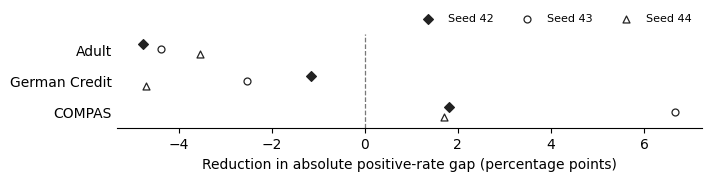

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.0, 1.7), layout="constrained")
styles = [(42, "D", -0.16), (43, "o", 0), (44, "^", 0.16)]
names = list(datasets)
for seed, marker, offset in styles:
    delta = comparison.xs(seed, level="seed").loc[names, "gap_reduction_pp"]
    ax.scatter(delta, np.arange(len(names)) + offset, marker=marker, s=25,
               facecolor="#222222" if seed == 42 else "white",
               edgecolor="#222222", linewidth=0.9, label=f"Seed {seed}", zorder=3)
ax.axvline(0, color="#777777", lw=0.9, ls="--")
ax.set_yticks(np.arange(len(names)), names)
ax.set_ylim(len(names) - 0.5, -0.5)
ax.set_xlabel("Reduction in absolute positive-rate gap (percentage points)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=3, frameon=False, fontsize=8)
fig.savefig(RESULTS / "split_comparison.png", dpi=220)
plt.show()